# Is the L2 of the assigned fish bimodal? (71 recordings, Denis' model; controls for reference)

Same L2 values as `EOD_L2_distributions_denis_71_4fish_kaden.ipynb` (`denis_71/denis_71_l2_per_eod.csv.gz`), drawn differently:
**linear L2 axis** with 100 equal bins, two **filled** histograms per panel — all EODs (grey) and good-mask EODs (fish colour) —
each normalised to its own total; once with a linear count axis and once with a **log** count axis, where a small second population
shows up as a second hump or a shoulder. n in every legend.

Reference (bottom rows): the 2-/3-fish controls, my model (Kaden masks, camera tank, interior 2 × water), shape L2 of the assigned
fish for correct and wrong EODs on the same axes — what errors look like where we know them.

3,667,494 EODs; with a shape pick 3,498,433; good masks 1,229,644


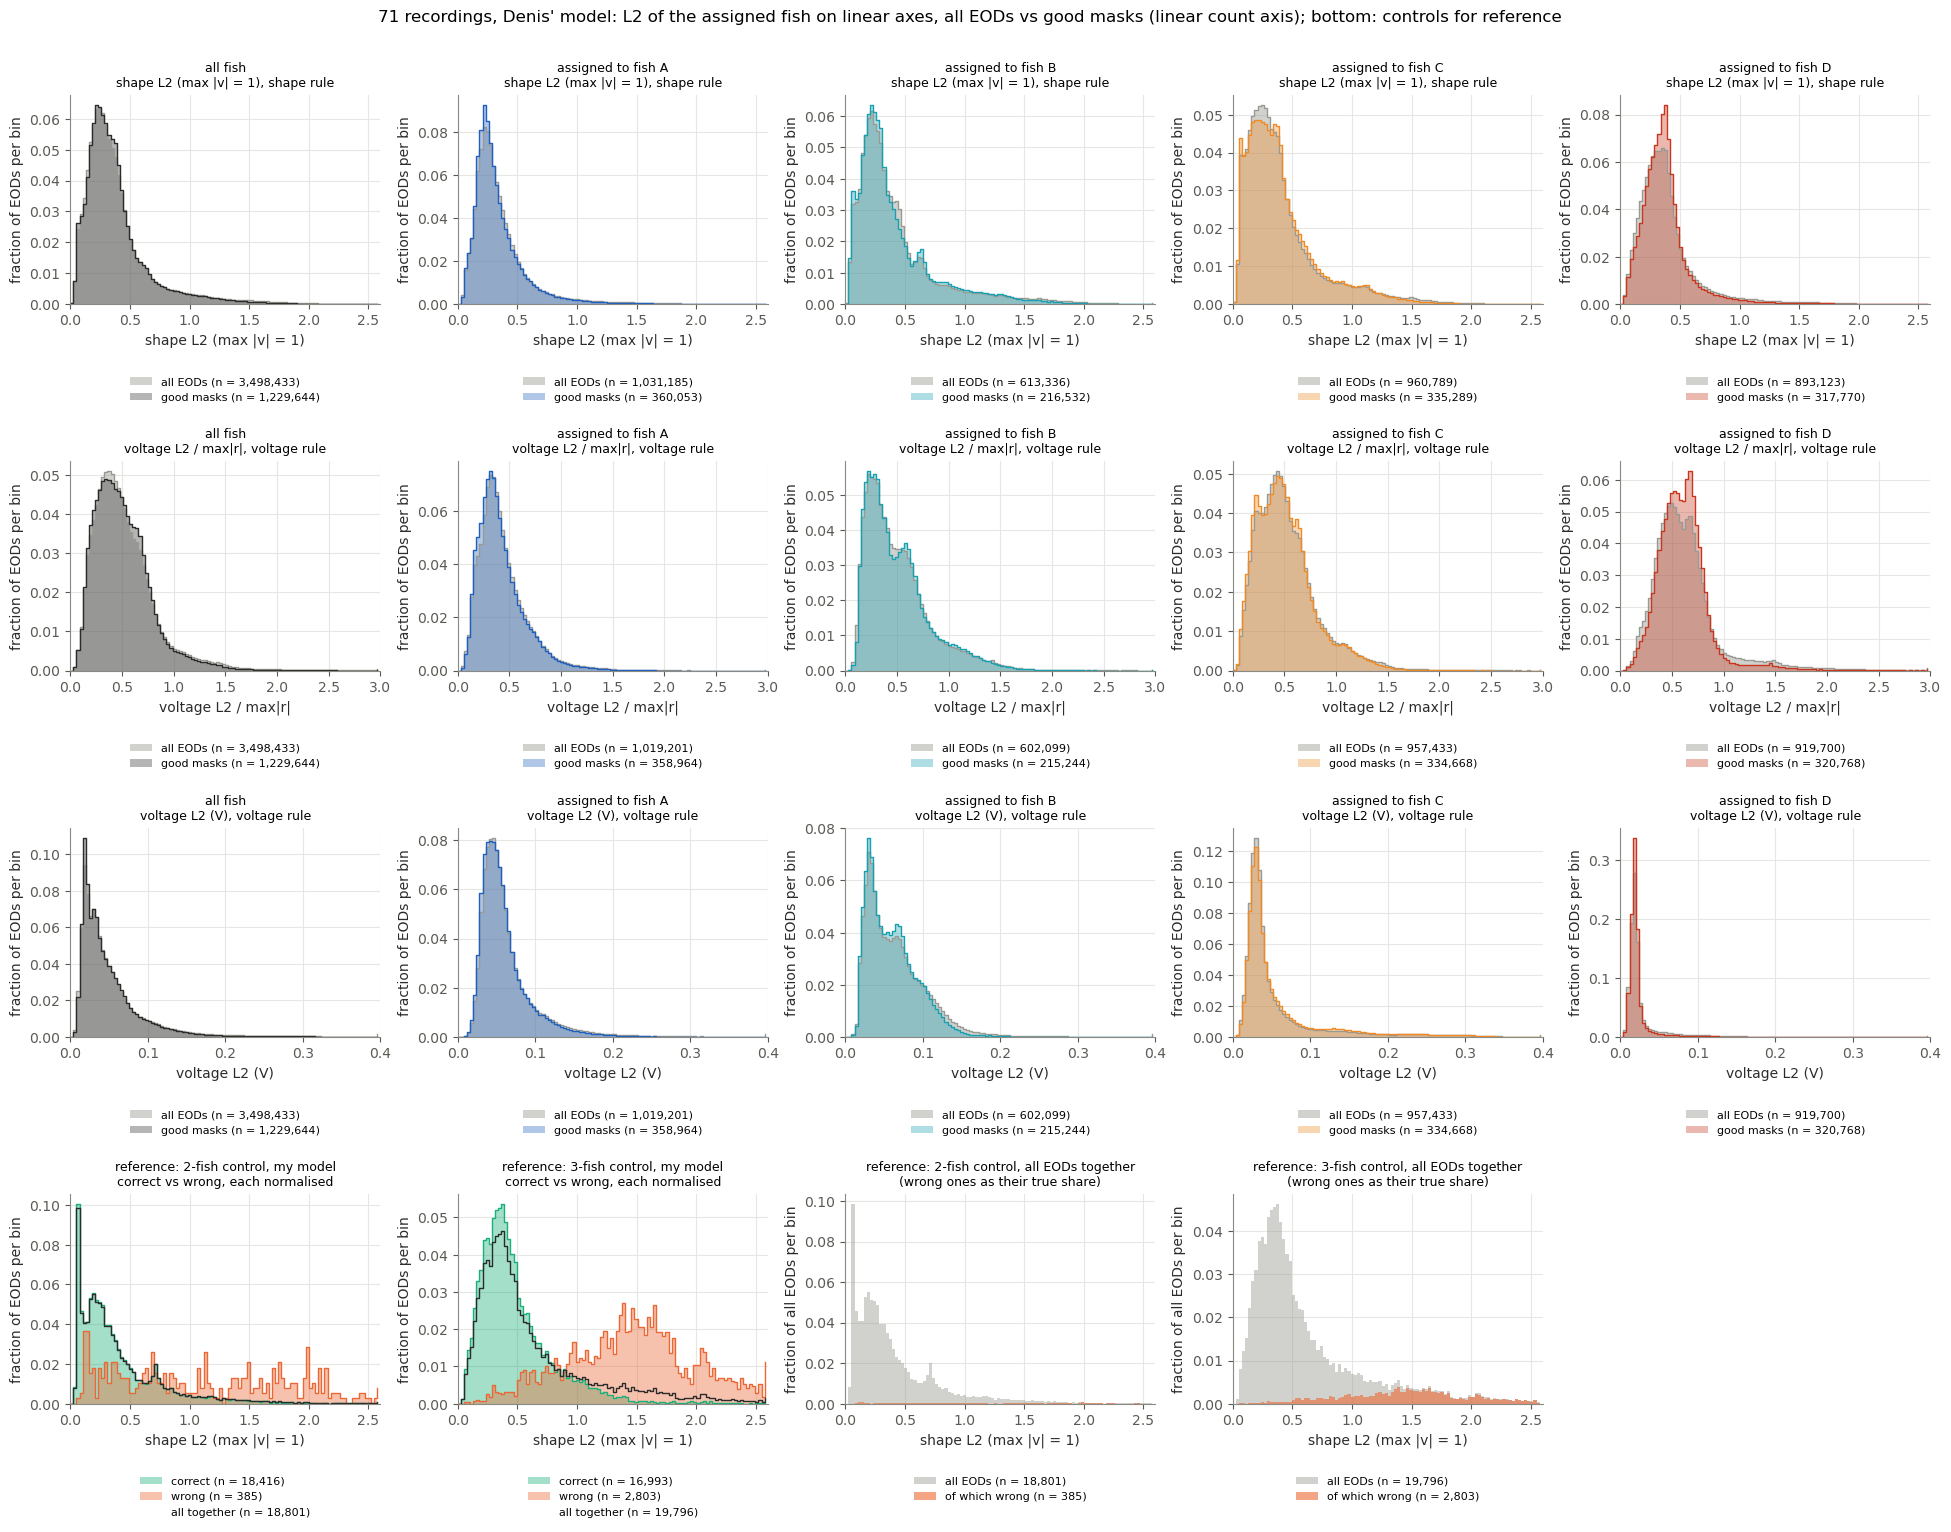

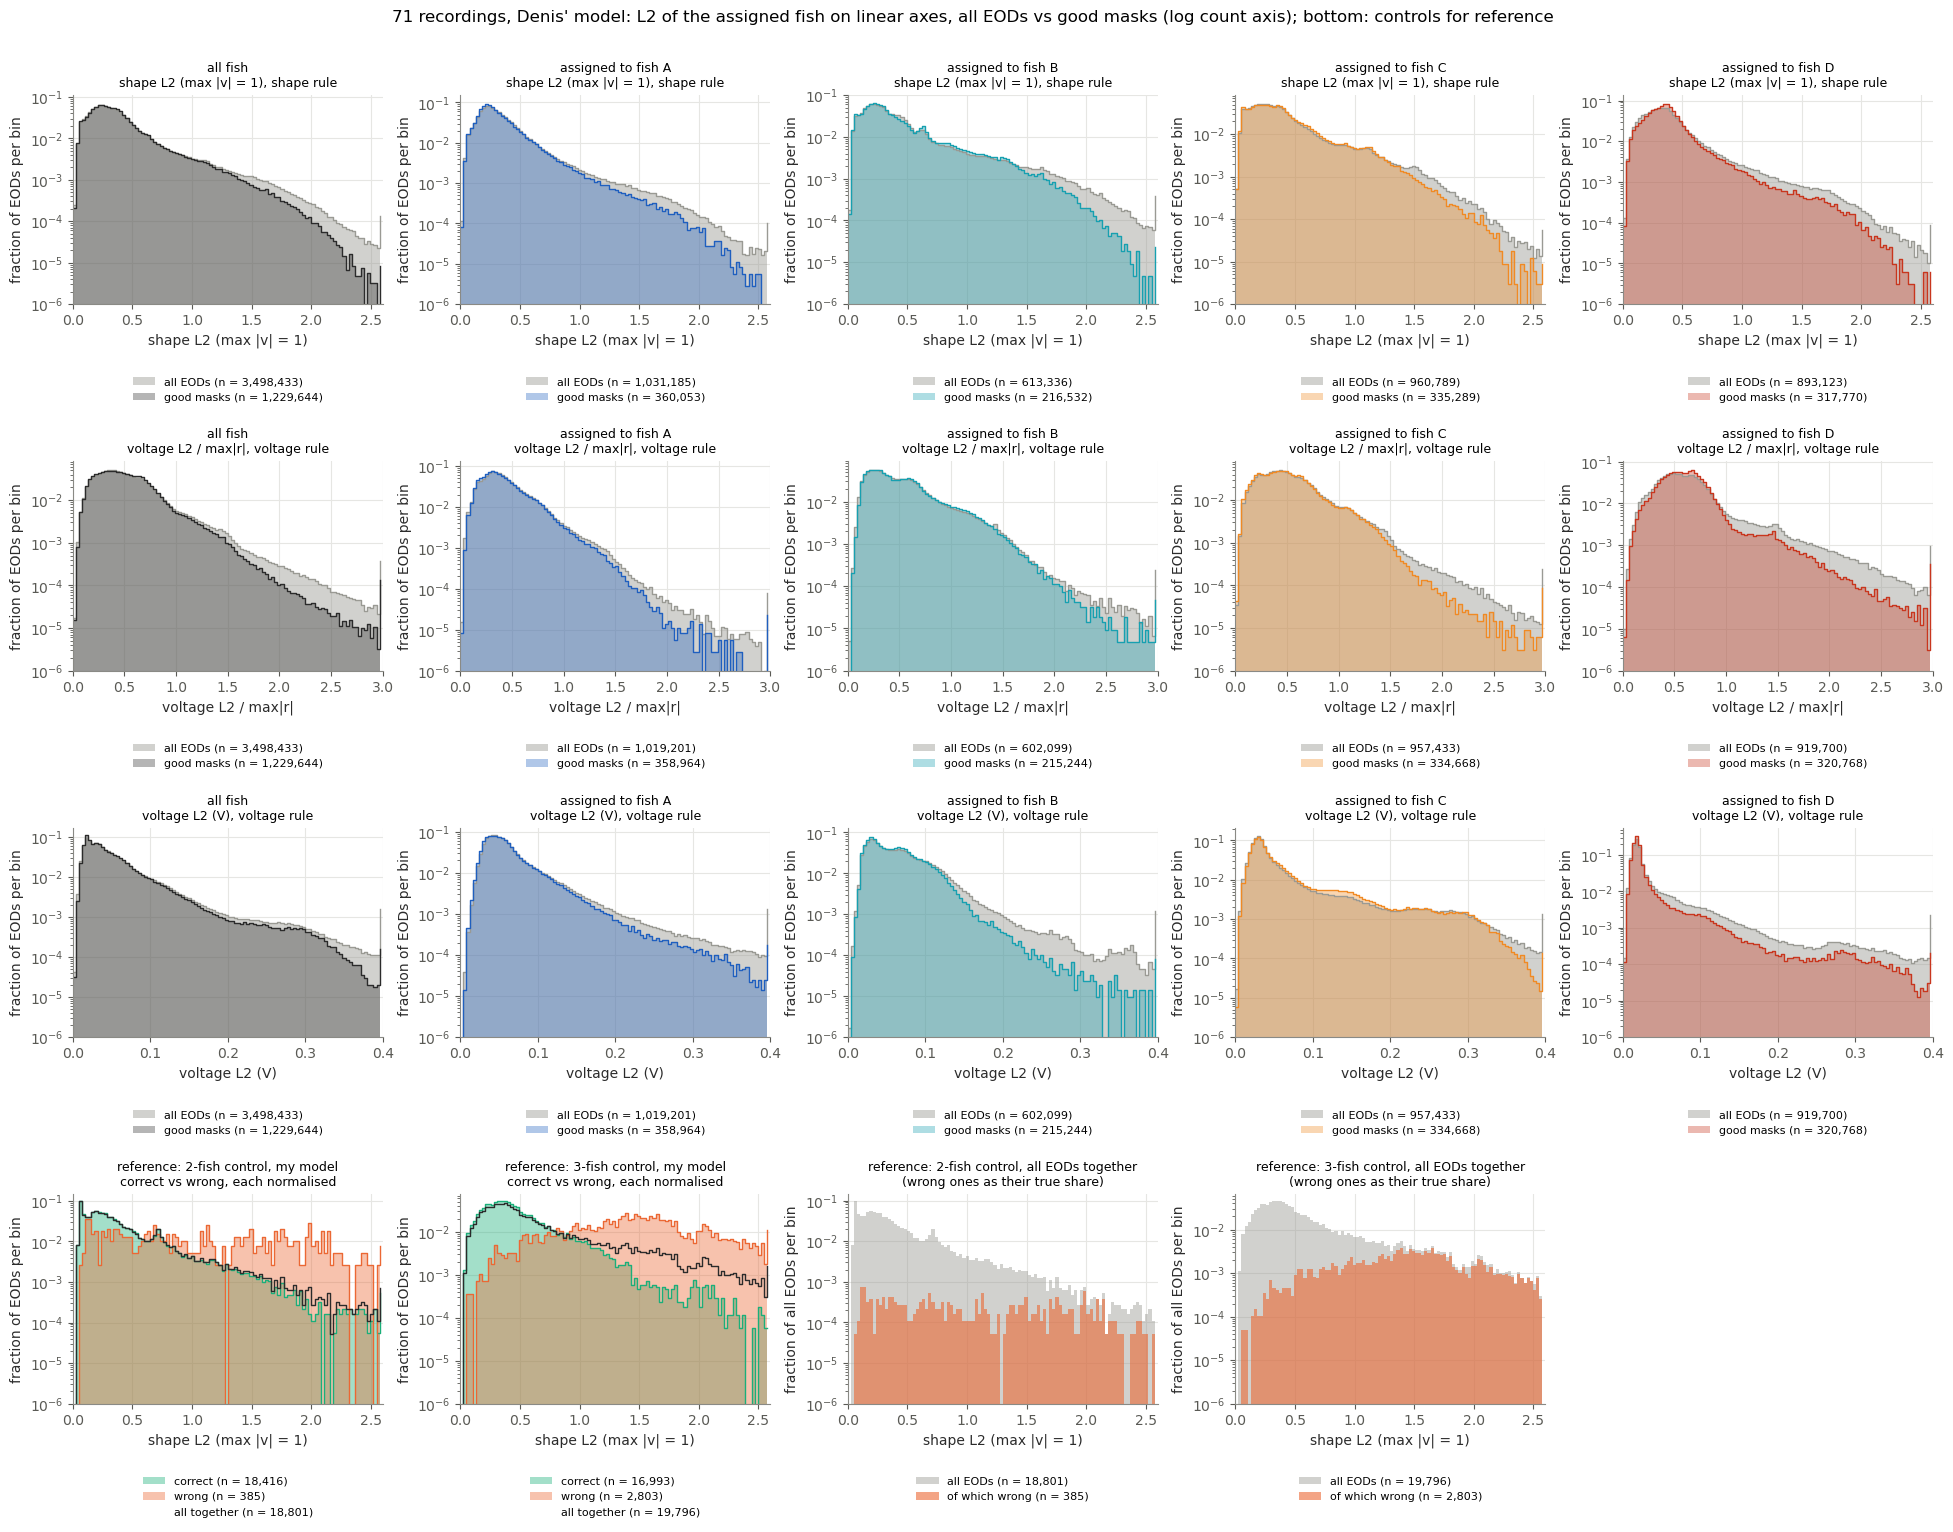

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
OUT = 'results/eod_assign_4fish_kaden/l2_distributions/denis_71'
LET = 'ABCD'; FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E', 'all': '#2b2b2b'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
DL = pd.read_csv(f'{OUT}/denis_71_l2_per_eod.csv.gz', keep_default_na=False, na_values=[''])
DL['pick_shape'] = DL.pick_shape.fillna(''); DL['pick_voltage'] = DL.pick_voltage.fillna('')
DL['good'] = DL.good.astype(str).str.lower().eq('true')
MEAS = {'shape': ('shape L2 (max |v| = 1), shape rule', 'pick_shape', 'l2_shape', np.linspace(0, 2.6, 101)),
        'rel': ('voltage L2 / max|r|, voltage rule', 'pick_voltage', 'l2_rel', np.linspace(0, 3, 101)),
        'volt': ('voltage L2 (V), voltage rule', 'pick_voltage', 'l2_volt', np.linspace(0, 0.4, 101))}
CTRL = {'2-fish': (2, 1), '3-fish': (3, 0)}
REF = {}
for name, (n, em) in CTRL.items():
    T = pd.read_csv(f'results/eod_assignment_{n}_fish_silent/with_Kaden_tracking/N150_tank_int2_none/eod_assignment_shape.csv'); T = T[T.pick >= 0]
    x = np.array([T[f'd{p}'].iloc[i] for i, p in enumerate(T.pick)]); REF[name] = (x, T.pick.to_numpy() == em)
print(f'{len(DL):,} EODs; with a shape pick {(DL.pick_shape != "").sum():,}; good masks {DL.good.sum():,}')

def fill(ax, x, bins, color, label, alpha):
    x = x[np.isfinite(x)]; h, _ = np.histogram(np.clip(x, bins[0], bins[-1] - 1e-12), bins=bins); h = h / max(len(x), 1)
    ax.fill_between(bins[:-1], h, step='post', color=color, alpha=alpha, lw=0, label=label)
    ax.step(bins[:-1], h, where='post', color=color, lw=1)

def figure(logy):
    fig, axs = plt.subplots(4, 5, figsize=(24, 17), gridspec_kw=dict(hspace=0.75, wspace=0.25))
    for r_, (m, (xlab, pk, col, bins)) in enumerate(MEAS.items()):
        d = DL[DL[pk] != '']
        for c_, f in enumerate(['all'] + list(LET)):
            ax = axs[r_, c_]; g = d if f == 'all' else d[d[pk] == f]; gg = g[g.good]
            fill(ax, g[col].to_numpy(), bins, '#9a9a94', f'all EODs (n = {len(g):,})', 0.45)
            fill(ax, gg[col].to_numpy(), bins, FISH_COL[f], f'good masks (n = {len(gg):,})', 0.35)
            ax.set(xlim=(bins[0], bins[-1]), yscale='log' if logy else 'linear', xlabel=xlab.split(',')[0], ylabel='fraction of EODs per bin')
            if logy: ax.set_ylim(1e-6, None)
            else: ax.set_ylim(0, None)
            ax.set_title(f'{"all fish" if f == "all" else "assigned to fish " + f}\n{xlab}', fontsize=9)
            ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.3))
    bins = MEAS['shape'][3]
    for c_, name in enumerate(CTRL):
        ax = axs[3, c_]; x, ok = REF[name]
        fill(ax, x[ok], bins, '#1baf7a', f'correct (n = {ok.sum():,})', 0.4); fill(ax, x[~ok], bins, '#eb6834', f'wrong (n = {(~ok).sum():,})', 0.4)
        fill(ax, x, bins, '#2b2b2b', f'all together (n = {len(x):,})', 0.0)
        ax.set(xlim=(bins[0], bins[-1]), yscale='log' if logy else 'linear', xlabel='shape L2 (max |v| = 1)', ylabel='fraction of EODs per bin')
        if logy: ax.set_ylim(1e-6, None)
        else: ax.set_ylim(0, None)
        ax.set_title(f'reference: {name} control, my model\ncorrect vs wrong, each normalised', fontsize=9)
        ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.3))
        # the same pooled with the true error share (not each group normalised)
        ax2 = axs[3, 2 + c_]; h_all, _ = np.histogram(np.clip(x, 0, bins[-1] - 1e-12), bins=bins); h_bad, _ = np.histogram(np.clip(x[~ok], 0, bins[-1] - 1e-12), bins=bins)
        ax2.fill_between(bins[:-1], h_all / len(x), step='post', color='#9a9a94', alpha=0.45, lw=0, label=f'all EODs (n = {len(x):,})')
        ax2.fill_between(bins[:-1], h_bad / len(x), step='post', color='#eb6834', alpha=0.6, lw=0, label=f'of which wrong (n = {(~ok).sum():,})')
        ax2.set(xlim=(bins[0], bins[-1]), yscale='log' if logy else 'linear', xlabel='shape L2 (max |v| = 1)', ylabel='fraction of all EODs per bin')
        if logy: ax2.set_ylim(1e-6, None)
        else: ax2.set_ylim(0, None)
        ax2.set_title(f'reference: {name} control, all EODs together\n(wrong ones as their true share)', fontsize=9)
        ax2.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.3))
    axs[3, 4].axis('off')
    fig.suptitle(f"71 recordings, Denis' model: L2 of the assigned fish on linear axes, all EODs vs good masks ({'log' if logy else 'linear'} count axis); "
                 'bottom: controls for reference', fontsize=12, y=0.93)
    fig.savefig(f'{OUT}/l2_denis_71_linear_{"logy" if logy else "liny"}.png', dpi=90, bbox_inches='tight'); plt.show()

figure(False); figure(True)